In [9]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

In [10]:
# Данные
data = {
'Возраст': [25, 30, 35, 40, 45, 50, 55],
'Доход': [50000, 60000, 65000, 70000, 80000, 90000, 85000],
'Купил': ['Нет', 'Нет', 'Да', 'Да', 'Да', 'Нет', 'Нет']
}

In [11]:
df=pd.DataFrame(data)

In [12]:
X=df[['Возраст','Доход']]
y=df['Купил'].map({'Нет':0,'Да':1})

In [13]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)

In [14]:
tree_model=DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train,y_train)
tree_pred=tree_model.predict(X_test)
tree_acc=accuracy_score(y_test,tree_pred)
print(f' Точность дерева решений: {tree_acc * 100:.2f}%')

 Точность дерева решений: 0.00%


In [15]:
forest_model=RandomForestClassifier(n_estimators=100,random_state=42)
forest_model.fit(X_train,y_train)
forest_pred=forest_model.predict(X_test)
forest_acc=accuracy_score(y_test,forest_pred)
print(f' Точность случайного леса: {tree_acc * 100:.2f}%')

 Точность случайного леса: 0.00%


In [23]:
new_client=pd.DataFrame({'Возраст': [81], 'Доход': [12000]})
tree_decision = tree_model.predict(new_client)
forest_decision = forest_model.predict(new_client)

In [24]:
print(f" Дерево решений: {'Купит' if tree_decision[0] == 1 else 'Не купит'}")
print(f" Случайный лес: {'Купит' if forest_decision[0] == 1 else 'Не купит'}")

 Дерево решений: Не купит
 Случайный лес: Купит


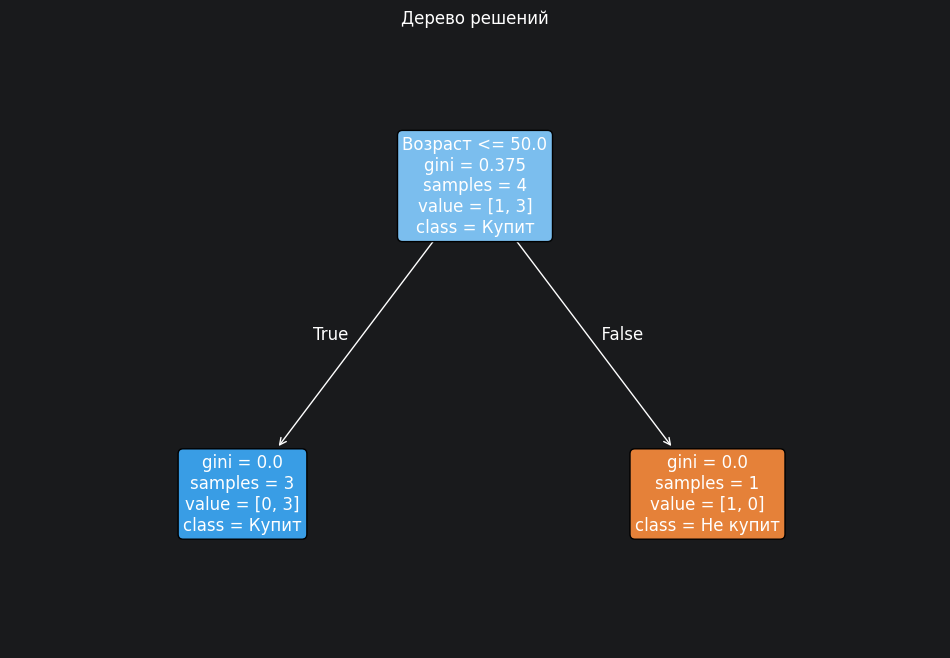

In [25]:
#Визуализация дерева решений
plt.figure(figsize=(12, 8))
plot_tree(tree_model, filled=True, feature_names=['Возраст', 'Доход'], class_names=['Не купит',
'Купит'], rounded=True, fontsize=12)
plt.title("Дерево решений")
plt.show()